In [96]:
import re
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
import rsatoolbox
import matplotlib.pyplot as plt
import json

In [97]:
config = json.load(open("probing_rsa_fasting_social_isolation/config.json"))

ROI_DIR = Path("probing_rsa_fasting_social_isolation/masks")
FIRST_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/first_level_nipype")
SECOND_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/second_level_nipype")

OUT_DIR = Path(
    "probing_rsa_fasting_social_isolation/results/rdms_thresh_80"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [98]:
ROI_COVERAGE_THRESHOLD = 0.80

# Lets not run a crossvalidated analysis with fewer than two independent runs
MIN_COMMON_RUNS = 2

# Exclude extremely tiny masks even if their proportional coverage is high.
MIN_VOXELS_ROI = 10

# If True, subtract each pattern's voxel mean before calculating distances.
REMOVE_PATTERN_MEAN = False

In [99]:
SESSION_MAP = {
    "b": "baseline",
    "f": "fasting",
    "s": "isolation",
}

STIMULI = {
    "food": "con_2_food_gt_rest_cope.nii.gz",
    "social": "con_4_social_gt_rest_cope.nii.gz",
    "flowers": "con_6_control_gt_rest_cope.nii.gz",
}

CONDITION_ORDER = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]

In [100]:
def split_subject_session(subject_session: str) -> tuple[str, str]:
    """
    SAXSISO01b -> ('SAXSISO01', 'b')
    """
    return subject_session[:-1], subject_session[-1]


def load_3d(path: Path) -> nib.Nifti1Image:
    img = nib.load(str(path))
    if img.ndim != 3:
        raise ValueError(f"Expected 3D image, found {img.ndim}D: {path}")
    return img


def same_grid(reference_img: nib.spatialimages.SpatialImage,
              test_img: nib.spatialimages.SpatialImage,
              atol: float = 1e-4) -> bool:
    return (
        reference_img.shape[:3] == test_img.shape[:3]
        and np.allclose(reference_img.affine, test_img.affine, atol=atol)
    )


def require_same_grid(reference_img, test_img, test_path: Path) -> None:
    if not same_grid(reference_img, test_img):
        raise ValueError(
            "\nGrid mismatch detected.\n"
            f"Reference shape: {reference_img.shape[:3]}\n"
            f"Test shape:      {test_img.shape[:3]}\n"
            f"Problem image:   {test_path}\n\n"
            "All cope maps, residuals, ROI masks, and run masks must be in "
            "the same MNI grid before extracting RSA patterns. Resample the "
            "data images with continuous interpolation and masks with nearest "
            "neighbor interpolation, then rerun."
        )


def get_mask_data(path: Path, reference_img: nib.Nifti1Image) -> np.ndarray:
    img = load_3d(path)
    require_same_grid(reference_img, img, path)
    return img.get_fdata() > 0


def run_dir_for(subject_session: str, run_label: str) -> Path:
    return FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model" /run_label


def available_run_labels(subject_session: str) -> list[str]:
    """
    Finds run1, run2, ... folders, retaining only folders with all three
    stimulus-vs-rest cope images.
    """
    cic_dir = FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model"

    if not cic_dir.exists():
        print(f"Directory does not exist: {cic_dir}")
        return []

    run_dirs = [
        p for p in cic_dir.iterdir()
        if p.is_dir() and re.fullmatch(r"run\d+", p.name)
    ]

    def run_number(path: Path) -> int:
        return int(re.search(r"\d+", path.name).group())

    run_dirs = sorted(run_dirs, key=run_number)

    complete_runs = []
    for run_dir in run_dirs:
        has_all_copes = all((run_dir / cope_name).exists()
                            for cope_name in STIMULI.values())
        if has_all_copes:
            complete_runs.append(run_dir.name)
        else:
            print(
                f"Skipping incomplete run: {run_dir}. "
                "At least one required cope is missing."
            )

    return complete_runs


def session_run_intersection_mask_path(subject_session: str) -> Path:
    """
    This is existing per-session intersection across that session's runs we saved after 1.5 level analysis.
    """
    folder = f"{subject_session}"
    return (
        SECOND_LEVEL_DIR
        / folder
        / "CIC"
        / "masks"
        / f"{folder}_CIC_run-intersection_mask.nii.gz"
    )


def build_joint_subject_mask(subject, roi_name):
    """
    ROI ∩ baseline run-intersection ∩ fasting run-intersection ∩ isolation run-intersection
    """
    session_masks = {}

    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        mask_path = session_run_intersection_mask_path(subject_session)

        if not mask_path.exists():
            raise FileNotFoundError(f"Missing run-intersection mask: {mask_path}")

        mask_img = load_3d(mask_path)
    
        session_masks[session_letter] = mask_img.get_fdata() > 0

    joint_run_mask = np.logical_and.reduce(list(session_masks.values()))

    roi_path = ROI_DIR / f"{roi_name}.gz"
    if not roi_path.exists():
        raise FileNotFoundError(f"ROI mask not found: {roi_path}")

    roi_mask = get_mask_data(roi_path, mask_img)
    if roi_mask.sum() == 0:
        raise ValueError(f"ROI is empty: {roi_name}")

    final_mask = roi_mask & joint_run_mask
    joint_coverage = final_mask.sum() / roi_mask.sum()

    return mask_img, final_mask, float(joint_coverage)


def get_common_runs(subject):
    runs_by_session = {}
    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        runs_by_session[session_letter] = set(available_run_labels(subject_session))

    common_runs = sorted(
        set.intersection(*runs_by_session.values()),
        key=lambda x: int(re.search(r"\d+", x).group()),
    )
    return common_runs

In [101]:
def extract_patterns_and_residuals(subject, analysis_mask, reference_img, common_runs):
    """
    Returns:
        measurements: (n_runs * n_conditions, n_voxels)  -- one row per run x condition
        condition_labels: (n_runs * n_conditions,)
        run_labels: (n_runs * n_conditions,)
    """
    rows_measurements = []
    rows_condition = []
    rows_run = []

    for run_label in common_runs:
        for session_letter, session_name in SESSION_MAP.items():
            subject_session = f"{subject}{session_letter}"
            run_dir = run_dir_for(subject_session, run_label)

            for stimulus_name, cope_filename in STIMULI.items():
                cope_path = run_dir / cope_filename
                if not cope_path.exists():
                    raise FileNotFoundError(f"Missing cope: {cope_path}")

                cope_img = load_3d(cope_path)
                require_same_grid(reference_img, cope_img, cope_path)
                cope_values = cope_img.get_fdata(dtype=np.float32)[analysis_mask]

                if not np.all(np.isfinite(cope_values)):
                    raise ValueError(f"Non-finite cope values: {cope_path}")

                condition_name = f"{stimulus_name}_{session_name}"

                rows_measurements.append(cope_values)
                rows_condition.append(condition_name)
                rows_run.append(run_label)
                # Same residual time series is shared by all 3 stimuli of this
                # session/run (they come from the same first-level GLM run).


    measurements = np.stack(rows_measurements, axis=0)
    condition_labels = np.array(rows_condition)
    run_labels = np.array(rows_run)

    return measurements, condition_labels, run_labels


In [102]:
def compute_subject_roi_rdm(subject, roi_name):

    reference_img, analysis_mask, joint_coverage = build_joint_subject_mask(subject, roi_name)
    n_voxels = int(analysis_mask.sum())

    common_runs = get_common_runs(subject)

    if joint_coverage < ROI_COVERAGE_THRESHOLD or n_voxels < MIN_VOXELS_ROI or len(common_runs) < MIN_COMMON_RUNS:
        return None, {
            "subject": subject,
            "roi": roi_name,
            "included": False,
            "n_voxels": n_voxels,
            "joint_coverage": joint_coverage,
            "common_runs": common_runs,
        }


    measurements, condition_labels, run_labels = extract_patterns_and_residuals(
        subject, analysis_mask, reference_img, common_runs
    )

    dataset = rsatoolbox.data.Dataset(
        measurements=measurements,
        obs_descriptors={"condition": condition_labels, "run": run_labels},
    )

    rdm_obj = rsatoolbox.rdm.calc_rdm(
        dataset,
        method="crossnobis",
        descriptor="condition",
        cv_descriptor="run",
        noise=None,
    )

    # Reorder to CONDITION_ORDER (calc_rdm sorts labels
    # alphabetically by default, not in intended order)
    rdm_obj.reorder(np.array([
        list(rdm_obj.pattern_descriptors["condition"]).index(c)
        for c in CONDITION_ORDER
    ]))

    rdm_matrix = rdm_obj.get_matrices()[0]

    dict_row = {
        "subject": subject,
        "roi": roi_name,
        "included": True,
        "n_voxels": n_voxels,
        "joint_coverage": joint_coverage,
        "common_runs": common_runs,
    }
    return rdm_matrix, dict_row


In [103]:
roi_names = [f.stem for f in ROI_DIR.glob("*.nii.gz")]
roi_names

['Frontal Pole.nii',
 'Insular Cortex.nii',
 'Superior Frontal Gyrus.nii',
 'Middle Frontal Gyrus.nii',
 'Inferior Frontal Gyrus, pars triangularis.nii',
 'Inferior Frontal Gyrus, pars opercularis.nii',
 'Precentral Gyrus.nii',
 'Temporal Pole.nii',
 'Superior Temporal Gyrus, anterior division.nii',
 'Superior Temporal Gyrus, posterior division.nii',
 'Middle Temporal Gyrus, anterior division.nii',
 'Middle Temporal Gyrus, posterior division.nii',
 'Middle Temporal Gyrus, temporooccipital part.nii',
 'Inferior Temporal Gyrus, anterior division.nii',
 'Inferior Temporal Gyrus, posterior division.nii',
 'Inferior Temporal Gyrus, temporooccipital part.nii',
 'Postcentral Gyrus.nii',
 'Superior Parietal Lobule.nii',
 'Supramarginal Gyrus, anterior division.nii',
 'Supramarginal Gyrus, posterior division.nii',
 'Angular Gyrus.nii',
 'Lateral Occipital Cortex, superior division.nii',
 'Lateral Occipital Cortex, inferior division.nii',
 'Intracalcarine Cortex.nii',
 'Frontal Medial Cortex.nii

In [104]:
len(roi_names)
# We use 3 atlases so some of the regions may overlap or be duplicated across atlases

74

In [105]:
subjects = sorted(set(f.stem[:-1] for f in Path(FIRST_LEVEL_DIR).glob("sub-*")))
subjects

['sub-SAXSISO01',
 'sub-SAXSISO02',
 'sub-SAXSISO03',
 'sub-SAXSISO04',
 'sub-SAXSISO08',
 'sub-SAXSISO09',
 'sub-SAXSISO10',
 'sub-SAXSISO11',
 'sub-SAXSISO12',
 'sub-SAXSISO13',
 'sub-SAXSISO14',
 'sub-SAXSISO15',
 'sub-SAXSISO17',
 'sub-SAXSISO18',
 'sub-SAXSISO19',
 'sub-SAXSISO21',
 'sub-SAXSISO22',
 'sub-SAXSISO24',
 'sub-SAXSISO26',
 'sub-SAXSISO27',
 'sub-SAXSISO28',
 'sub-SAXSISO30',
 'sub-SAXSISO32',
 'sub-SAXSISO33',
 'sub-SAXSISO34',
 'sub-SAXSISO35',
 'sub-SAXSISO36',
 'sub-SAXSISO38',
 'sub-SAXSISO39',
 'sub-SAXSISO40',
 'sub-SAXSISO41',
 'sub-SAXSISO42']

In [106]:
len(subjects)

32

In [107]:
n_sub, n_roi, n = len(subjects), len(roi_names), len(CONDITION_ORDER)
rdms = np.full((n_sub, n_roi, n, n), np.nan)

rows = []

for i, subject in enumerate(subjects):
    for j, roi_name in enumerate(roi_names):
        print(f"Processing subject={subject}, roi={roi_name}")
        rdm, dict_row = compute_subject_roi_rdm(subject, roi_name)
        if rdm is not None:
            rdms[i, j] = rdm
        rows.append(dict_row)

np.savez_compressed(
    OUT_DIR / "crossnobis_rdms.npz",
    rdms=rdms,
    subjects=np.array(subjects),
    rois=np.array(roi_names),
    conditions=np.array(CONDITION_ORDER),
)

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "rdm_metadata.csv", index=False)


Processing subject=sub-SAXSISO01, roi=Frontal Pole.nii
Processing subject=sub-SAXSISO01, roi=Insular Cortex.nii
Processing subject=sub-SAXSISO01, roi=Superior Frontal Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Middle Frontal Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Inferior Frontal Gyrus, pars triangularis.nii
Processing subject=sub-SAXSISO01, roi=Inferior Frontal Gyrus, pars opercularis.nii
Processing subject=sub-SAXSISO01, roi=Precentral Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Temporal Pole.nii
Processing subject=sub-SAXSISO01, roi=Superior Temporal Gyrus, anterior division.nii
Processing subject=sub-SAXSISO01, roi=Superior Temporal Gyrus, posterior division.nii
Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, anterior division.nii
Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, posterior division.nii
Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, temporooccipital part.nii
Processing subject=sub-SAXSISO01, roi=Inferior Tempor

/local/anpa/LAB_IMMERSION/venv_lab_immersion/lib/python3.10/site-packages/rsatoolbox/data/computations.py:36: RuntimeWarning: invalid value encountered in multiply
  average = np.nan * np.empty(


Processing subject=sub-SAXSISO03, roi=Middle Temporal Gyrus, temporooccipital part.nii
Processing subject=sub-SAXSISO03, roi=Inferior Temporal Gyrus, anterior division.nii
Processing subject=sub-SAXSISO03, roi=Inferior Temporal Gyrus, posterior division.nii
Processing subject=sub-SAXSISO03, roi=Inferior Temporal Gyrus, temporooccipital part.nii
Processing subject=sub-SAXSISO03, roi=Postcentral Gyrus.nii
Processing subject=sub-SAXSISO03, roi=Superior Parietal Lobule.nii
Processing subject=sub-SAXSISO03, roi=Supramarginal Gyrus, anterior division.nii
Processing subject=sub-SAXSISO03, roi=Supramarginal Gyrus, posterior division.nii
Processing subject=sub-SAXSISO03, roi=Angular Gyrus.nii
Processing subject=sub-SAXSISO03, roi=Lateral Occipital Cortex, superior division.nii
Processing subject=sub-SAXSISO03, roi=Lateral Occipital Cortex, inferior division.nii
Processing subject=sub-SAXSISO03, roi=Intracalcarine Cortex.nii
Processing subject=sub-SAXSISO03, roi=Frontal Medial Cortex.nii
Process

In [108]:
rdms.shape

(32, 74, 9, 9)

In [109]:
df

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Frontal Pole.nii,True,5709,0.822385,"[run1, run2, run5, run6]"
1,sub-SAXSISO01,Insular Cortex.nii,True,977,1.000000,"[run1, run2, run5, run6]"
2,sub-SAXSISO01,Superior Frontal Gyrus.nii,True,2208,0.937978,"[run1, run2, run5, run6]"
3,sub-SAXSISO01,Middle Frontal Gyrus.nii,True,2224,0.982332,"[run1, run2, run5, run6]"
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis.nii",True,605,0.946792,"[run1, run2, run5, run6]"
...,...,...,...,...,...,...
2363,sub-SAXSISO42,HN.nii,False,3,1.000000,"[run1, run2, run3, run4, run5, run6]"
2364,sub-SAXSISO42,HTH.nii,True,133,0.963768,"[run1, run2, run3, run4, run5, run6]"
2365,sub-SAXSISO42,MN.nii,True,11,1.000000,"[run1, run2, run3, run4, run5, run6]"
2366,sub-SAXSISO42,STH.nii,True,19,1.000000,"[run1, run2, run3, run4, run5, run6]"


In [110]:
df.query('included == False').roi.value_counts()

roi
Temporal Pole.nii                                     32
Inferior Temporal Gyrus, anterior division.nii        32
Inferior Temporal Gyrus, posterior division.nii       32
Temporal Fusiform Cortex, anterior division.nii       32
HN.nii                                                32
Occipital Pole.nii                                    32
Temporal Fusiform Cortex, posterior division.nii      32
Inferior Temporal Gyrus, temporooccipital part.nii    29
Parahippocampal Gyrus, anterior division.nii          28
Frontal Orbital Cortex.nii                            21
Cerebral Cortex.nii                                   19
Middle Temporal Gyrus, anterior division.nii          16
Brain-Stem.nii                                        15
Subcallosal Cortex.nii                                12
Frontal Pole.nii                                       9
SNr.nii                                                5
SNc_VTA.nii                                            4
PBP.nii                    

In [111]:
df.query('included')

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Frontal Pole.nii,True,5709,0.822385,"[run1, run2, run5, run6]"
1,sub-SAXSISO01,Insular Cortex.nii,True,977,1.000000,"[run1, run2, run5, run6]"
2,sub-SAXSISO01,Superior Frontal Gyrus.nii,True,2208,0.937978,"[run1, run2, run5, run6]"
3,sub-SAXSISO01,Middle Frontal Gyrus.nii,True,2224,0.982332,"[run1, run2, run5, run6]"
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis.nii",True,605,0.946792,"[run1, run2, run5, run6]"
...,...,...,...,...,...,...
2362,sub-SAXSISO42,VeP.nii,True,10,1.000000,"[run1, run2, run3, run4, run5, run6]"
2364,sub-SAXSISO42,HTH.nii,True,133,0.963768,"[run1, run2, run3, run4, run5, run6]"
2365,sub-SAXSISO42,MN.nii,True,11,1.000000,"[run1, run2, run3, run4, run5, run6]"
2366,sub-SAXSISO42,STH.nii,True,19,1.000000,"[run1, run2, run3, run4, run5, run6]"


In [112]:
df.query('included').roi.value_counts()

roi
Insular Cortex.nii                                    32
Superior Frontal Gyrus.nii                            32
Middle Frontal Gyrus.nii                              32
STH.nii                                               32
Inferior Frontal Gyrus, pars triangularis.nii         32
                                                      ..
Middle Temporal Gyrus, anterior division.nii          16
Cerebral Cortex.nii                                   13
Frontal Orbital Cortex.nii                            11
Parahippocampal Gyrus, anterior division.nii           4
Inferior Temporal Gyrus, temporooccipital part.nii     3
Name: count, Length: 67, dtype: int64

In [113]:
len(df.query('included').roi.value_counts())

67

In [114]:
d = np.load(OUT_DIR / "crossnobis_rdms.npz")
d

NpzFile 'probing_rsa_fasting_social_isolation/results/rdms_thresh_80/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions

In [115]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Pu.nii")]
rdm

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [116]:
def plot_rdm(rdm_matrix, subject, roi_name):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(rdm_matrix, cmap="viridis")
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_yticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=90)
    ax.set_yticklabels(CONDITION_ORDER)
    ax.set_title(f"sub-{subject} | {roi_name}")
    fig.colorbar(im, ax=ax, label="crossnobis distance")
    fig.tight_layout()

    plt.show()
    plt.close(fig)

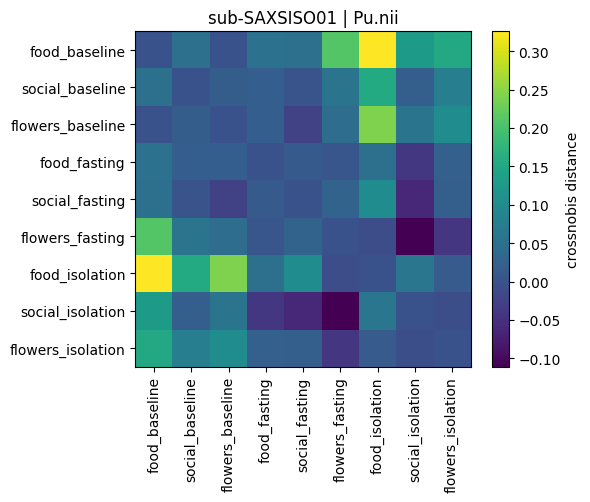

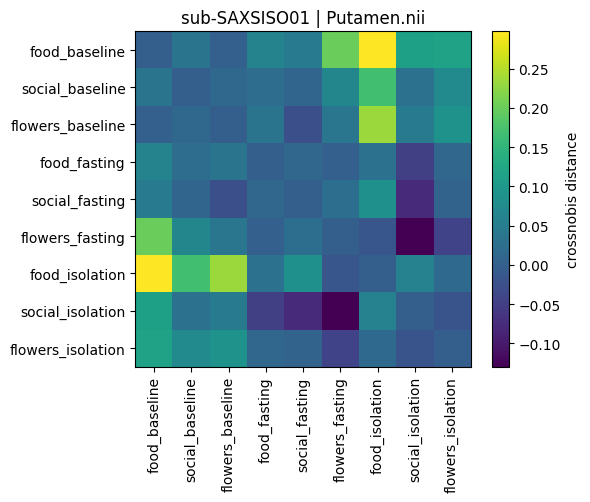

In [117]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Pu.nii")]
plot_rdm(rdm, "SAXSISO01", "Pu.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Putamen.nii")]
plot_rdm(rdm, "SAXSISO01", "Putamen.nii")
# Different atlases (could be different roi borders). I checked different subjects and the pattern holds

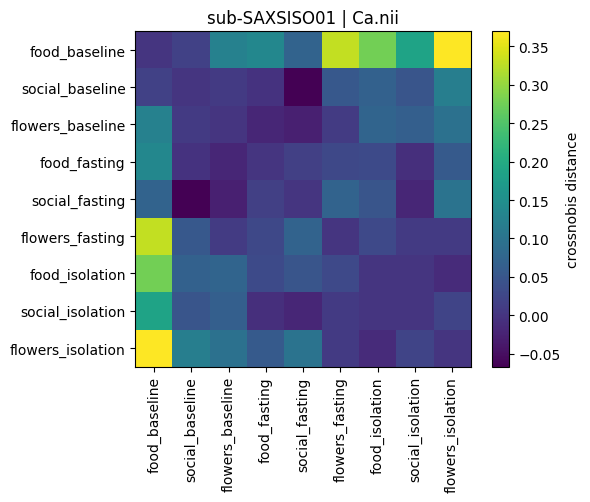

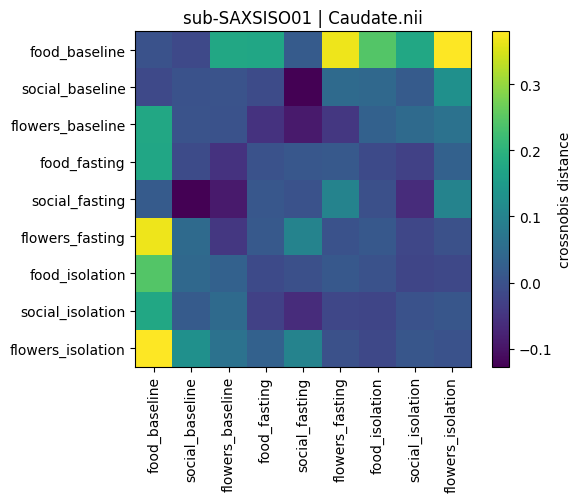

In [118]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Ca.nii")]
plot_rdm(rdm, "SAXSISO01", "Ca.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Caudate.nii")]
plot_rdm(rdm, "SAXSISO01", "Caudate.nii")
# Different atlases (could be different roi borders). I checked different subjects and the pattern holds

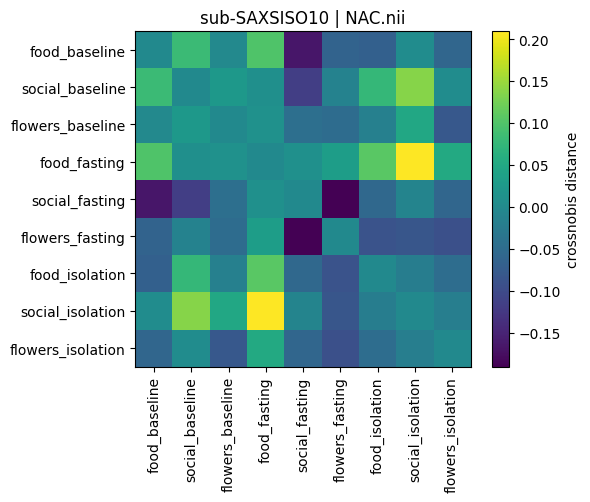

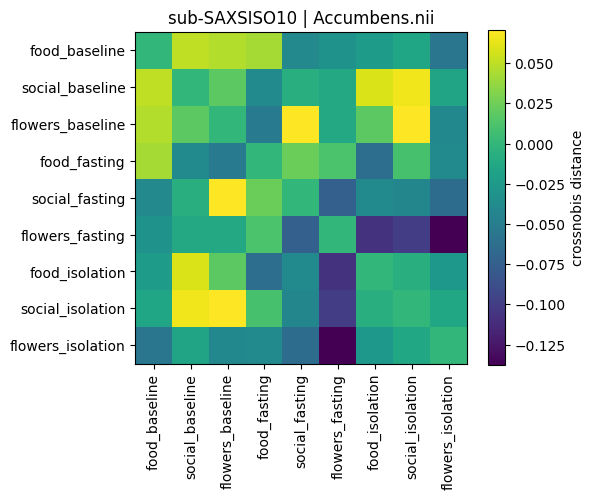

In [119]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO10"), list(d["rois"]).index("NAC.nii")]
plot_rdm(rdm, "SAXSISO10", "NAC.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO10"), list(d["rois"]).index("Accumbens.nii")]
plot_rdm(rdm, "SAXSISO10", "Accumbens.nii")
# In this ROI pattern does not seem to hold as clearly as in other ROIs
# Lets just leave all roi, and group them ba atlas for further analysis, for example do fdr correction within atlas